# 04. JPEG and the full camera

The last box of the camera pixel pipeline (L2 s3) stores the picture as a JPEG. We open that box first: colour transform, chroma subsampling, 8x8 DCT, quantisation and entropy coding (L5 s19-22), using `isp.jpeg`, which is a from-scratch codec checked against Pillow. Then we put all thirteen stages together with `isp.pipeline`, look at what each one does to the picture, measure it against the ground truth, change parameters, switch stages off and swap their order. Theory: `docs/07_compression.md`, `docs/00_camera_pipeline.md`, `docs/08_pipeline_experiments.md`.

In [1]:
%matplotlib inline
# JPEG keeps the executed notebooks small (plots are photographs).
%config InlineBackend.figure_format = 'jpeg'
import sys, pathlib, time
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 80
# Make `import isp` work whether Jupyter was started in the project root or in notebooks/.
_cwd = pathlib.Path.cwd().resolve()
ROOT = _cwd.parent if _cwd.name == 'notebooks' else _cwd
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import isp
from isp import utils, scenes
srgb = utils.linear_to_srgb      # linear light -> display values for imshow


def show_row(images, titles, figsize=(12, 4), cmap=None, vmin=None, vmax=None):
    # one row of image panels, axes off
    fig, axs = plt.subplots(1, len(images), figsize=figsize)
    for ax, im, t in zip(np.atleast_1d(axs), images, titles):
        ax.imshow(np.clip(im, 0, 1) if (vmin is None and im.ndim == 3) else im,
                  cmap=cmap, vmin=vmin, vmax=vmax, interpolation='nearest')
        ax.set_title(t, fontsize=10)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

from isp import jpeg, display, pipeline as P
import ipywidgets as W

clean = srgb(scenes.load('astronaut', 256))          # display-referred photo to feed the codec
print('stages of the default camera:', P.default_pipeline().names)

stages of the default camera: ['scene', 'illuminant', 'cfa', 'exposure', 'adc', 'black_level', 'hot_pixels', 'white_balance', 'demosaic', 'denoise', 'tonemap', 'sharpen', 'jpeg']


## Colour transform and chroma subsampling (L5 s20)

JPEG first converts RGB to YCbCr: one brightness plane and two colour-difference planes. The eye resolves colour detail poorly (notebook 02), so the colour planes are stored at lower resolution. `4:2:0` keeps one chroma sample per 2x2 pixels.

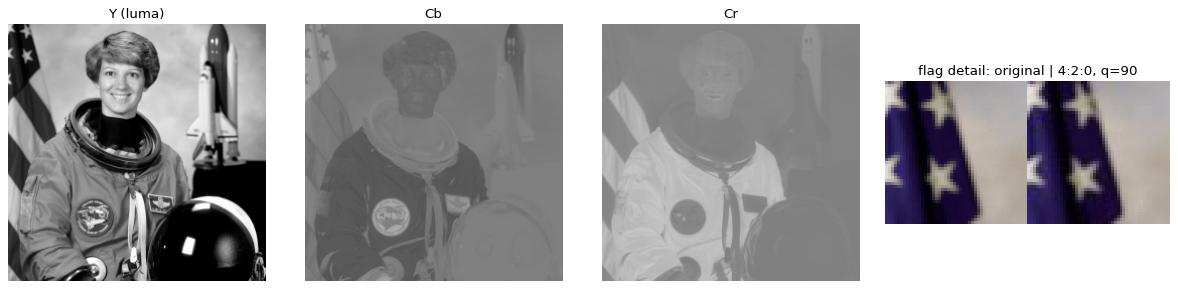

4:4:4:  26434 bytes, PSNR 38.4 dB
4:2:2:  23045 bytes, PSNR 36.6 dB
4:2:0:  20938 bytes, PSNR 35.5 dB


In [2]:
def subsampling_demo(img, quality=90, plot=True):
    ycc = utils.rgb_to_ycbcr(img)
    rows = {}
    outs = {}
    for mode in ('4:4:4', '4:2:2', '4:2:0'):
        out, info = jpeg.roundtrip(img, quality, mode)
        outs[mode] = out
        rows[mode] = (info['nbytes'], info['psnr'])
    if plot:
        fig, axs = plt.subplots(1, 4, figsize=(15, 3.6))
        for ax, k, t in zip(axs[:3], range(3), ['Y (luma)', 'Cb', 'Cr']):
            ax.imshow(ycc[..., k], cmap='gray', vmin=0, vmax=1); ax.set_title(t); ax.axis('off')
        sl = (slice(0, 48), slice(0, 48))                       # flag stripes: saturated colour edges
        axs[3].imshow(np.concatenate([img[sl], outs['4:2:0'][sl]], axis=1), interpolation='nearest')
        axs[3].set_title('flag detail: original | 4:2:0, q=%d' % quality); axs[3].axis('off')
        plt.tight_layout(); plt.show()
    return rows

rows = subsampling_demo(clean)
for k, (nb, ps) in rows.items():
    print(f'{k}: {nb:6d} bytes, PSNR {ps:.1f} dB')

Y carries the picture, Cb and Cr look like soft sketches. Going from 4:4:4 to 4:2:0 saves a good share of the file for a small PSNR change; the cost shows up only on thin saturated colour edges such as the red and blue flag stripes (right panel).

## One 8x8 block through DCT and quantisation (L5 s20)

The DCT re-expresses a block as a sum of 64 cosine patterns; quantisation divides each coefficient by a table entry and rounds, which is the only lossy step. High-frequency entries have big divisors, so most of them become zero.

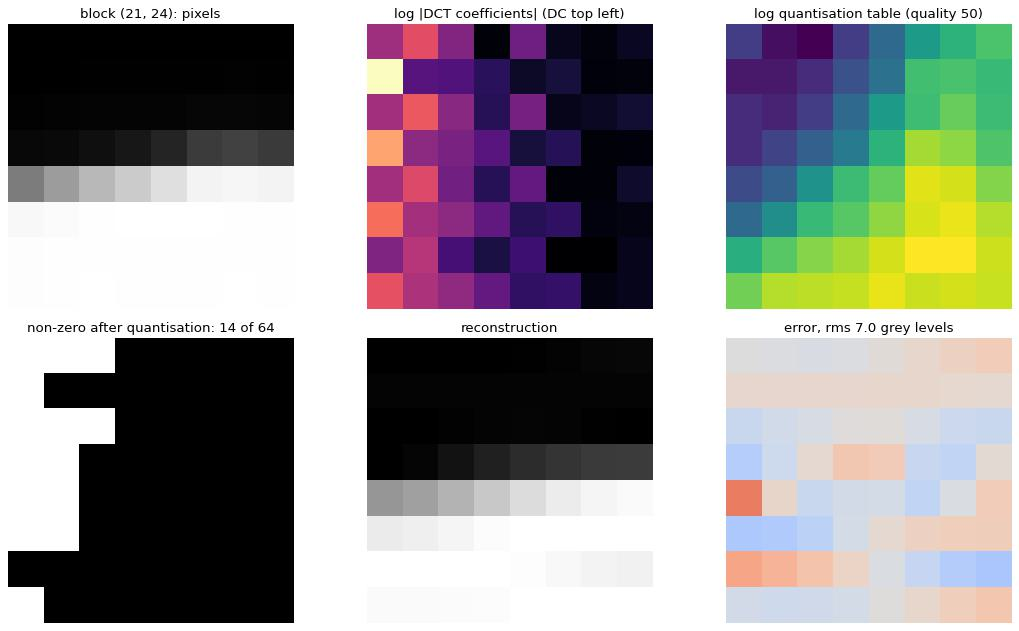

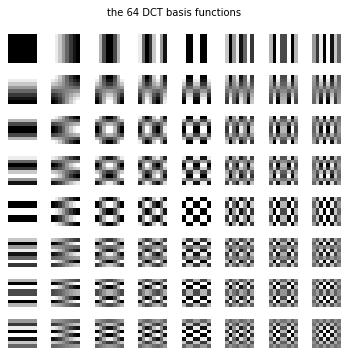

quantised block (integers):
 [[ -1  -6  -1   0   0   0   0   0]
 [-74   0   0   0   0   0   0   0]
 [  2   6   1   0   0   0   0   0]
 [ 18  -1   0   0   0   0   0   0]
 [ -1  -3   0   0   0   0   0   0]
 [ -5   1   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0]
 [  1   0   0   0   0   0   0   0]]


In [3]:
def block_demo(img, quality=50, plot=True):
    gray = utils.luminance(img)
    # pick the 8x8 block with the most structure (largest variance)
    v = jpeg.split_blocks(gray[:gray.shape[0] // 8 * 8, :gray.shape[1] // 8 * 8]).reshape(-1, 64).var(axis=1)
    k = int(np.argmax(v)); nbx = gray.shape[1] // 8
    blk = (k // nbx, k % nbx)
    r = jpeg.block_before_after(gray, blk, quality)
    if plot:
        fig, axs = plt.subplots(2, 3, figsize=(14, 8))
        axs[0, 0].imshow(r['pixels'], cmap='gray', vmin=0, vmax=255); axs[0, 0].set_title(f'block {blk}: pixels')
        axs[0, 1].imshow(np.log1p(np.abs(r['coefs'])), cmap='magma'); axs[0, 1].set_title('log |DCT coefficients| (DC top left)')
        axs[0, 2].imshow(np.log1p(r['q']), cmap='viridis'); axs[0, 2].set_title(f'log quantisation table (quality {quality})')
        axs[1, 0].imshow(np.abs(r['quantised']) > 0, cmap='gray'); axs[1, 0].set_title(f"non-zero after quantisation: {int((r['quantised'] != 0).sum())} of 64")
        axs[1, 1].imshow(r['recon'], cmap='gray', vmin=0, vmax=255); axs[1, 1].set_title('reconstruction')
        im = axs[1, 2].imshow(r['error'], cmap='coolwarm', vmin=-40, vmax=40); axs[1, 2].set_title(f"error, rms {np.sqrt(np.mean(r['error'] ** 2)):.1f} grey levels")
        for ax in axs.ravel(): ax.axis('off')
        plt.tight_layout(); plt.show()
        B = jpeg.dct_basis()
        fig, axs = plt.subplots(8, 8, figsize=(4.5, 4.5))
        for u in range(8):
            for w in range(8):
                axs[u, w].imshow(B[u, w], cmap='gray'); axs[u, w].axis('off')
        plt.suptitle('the 64 DCT basis functions', fontsize=9); plt.tight_layout(); plt.show()
    return r

r = block_demo(clean)
print('quantised block (integers):\n', r['quantised'])

The energy of a real image block concentrates in the low frequencies (top left), so after quantisation only a handful of integers survive, and the reconstruction is close to the block with an error spread over its pixels. A lower quality number means a bigger table, more zeros and a larger error.

## Entropy coding

The integers are read in zig-zag order (low to high frequency), so the zeros pile up at the end. Runs of zeros and the size of the next value form `(run, size)` symbols, which Huffman coding stores with short codes for common symbols. The DC coefficients are coded as differences between neighbouring blocks.

zig-zag order of the block above: [-1, -6, -74, 2, 0, -1, 0, 0, 6, 18, -1, -1, 1, 0, 0, 0, 0, 0, 0, -3, -5, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
(run, size, amplitude bits) symbols, first 8 of 14: [(0, 3, 1), (0, 7, 53), (0, 2, 2), (1, 1, 0), (2, 3, 6), (0, 5, 18), (0, 1, 0), (0, 1, 0)] ... the last symbol is end-of-block (0, 0, 0)


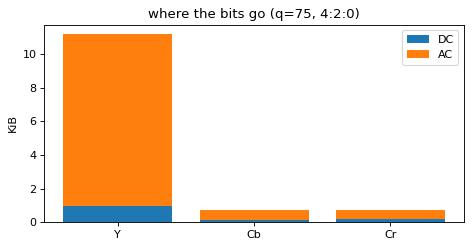

13346 bytes = 1.63 bits per pixel, 14.7:1 against 24 bpp, PSNR 32.5 dB


In [4]:
def entropy_demo(img, quality=75, plot=True):
    out, info = jpeg.roundtrip(img, quality)
    return info

blk = r['quantised']
zz = jpeg.zigzag(blk)
print('zig-zag order of the block above:', zz.tolist())
syms = jpeg.rle_encode_ac(zz[1:])
print('(run, size, amplitude bits) symbols, first 8 of %d:' % len(syms), syms[:8], '... the last symbol is end-of-block (0, 0, 0)' if syms[-1] == (0, 0, 0) else '')

info = entropy_demo(clean)
bits = info['bits']
fig, ax = plt.subplots(figsize=(6, 3.2))
bottom = np.zeros(3)
for part, col in (('DC', 'tab:blue'), ('AC', 'tab:orange')):
    vals = np.array([bits[c][part] for c in ('Y', 'Cb', 'Cr')]) / 8 / 1024
    ax.bar(['Y', 'Cb', 'Cr'], vals, bottom=bottom, label=part, color=col); bottom += vals
ax.set_ylabel('KiB'); ax.legend(); ax.set_title('where the bits go (q=75, 4:2:0)'); plt.tight_layout(); plt.show()
print(f"{info['nbytes']} bytes = {info['bpp']:.2f} bits per pixel, {info['ratio']:.1f}:1 against 24 bpp, PSNR {info['psnr']:.1f} dB")

Almost all of the bits are AC coefficients of Y: that is where the picture detail (and, in a noisy picture, the noise) lives. The two chroma planes together take a small share, which is the payoff of subsampling and heavy chroma quantisation.

## Quality sweep and rate-distortion (L5 s19-20)

Our codec estimates the file size from optimal Huffman tables. Real libjpeg (through Pillow) is the reference: if both land on the same rate-distortion curve the implementation is trustworthy.

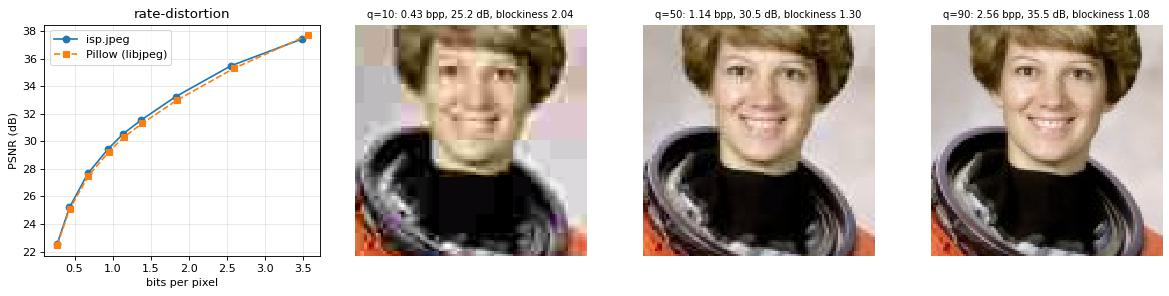

max |bpp difference| between our codec and libjpeg: 2.1 %


In [5]:
def quality_sweep(img, qualities=(5, 10, 20, 35, 50, 65, 80, 90, 95), plot=True):
    own, ref = [], []
    for q in qualities:
        out, info = jpeg.roundtrip(img, q)
        own.append((info['bpp'], info['psnr']))
        o2, nb = jpeg.pillow_roundtrip(img, q)
        ref.append((8.0 * nb / (img.shape[0] * img.shape[1]), utils.psnr(img, o2)))
    if plot:
        fig, axs = plt.subplots(1, 4, figsize=(15, 3.8))
        axs[0].plot(*zip(*own), 'o-', label='isp.jpeg'); axs[0].plot(*zip(*ref), 's--', label='Pillow (libjpeg)')
        axs[0].set_xlabel('bits per pixel'); axs[0].set_ylabel('PSNR (dB)'); axs[0].legend(); axs[0].grid(alpha=.3); axs[0].set_title('rate-distortion')
        for ax, q in zip(axs[1:], (10, 50, 90)):
            out, info = jpeg.roundtrip(img, q)
            ax.imshow(out[30:130, 60:160], interpolation='nearest'); ax.axis('off')
            ax.set_title(f"q={q}: {info['bpp']:.2f} bpp, {info['psnr']:.1f} dB, blockiness {jpeg.blockiness(out):.2f}", fontsize=9)
        plt.tight_layout(); plt.show()
    return own, ref

own, ref = quality_sweep(clean)
print('max |bpp difference| between our codec and libjpeg: %.1f %%' % (100 * max(abs(a[0] / b[0] - 1) for a, b in zip(own, ref))))

The two curves nearly coincide, so the codec does what libjpeg does. Along the curve, going from quality 90 to 50 buys a lot of bits for a moderate PSNR drop, and below about 20 the 8x8 grid becomes visible as blocks (the blockiness score rises above 1).

## Generation loss (L5 s19)

Every time a JPEG is opened, edited and saved again, it is encoded once more. If the picture lands on exactly the same 8x8 grid, the second encode is almost a projection and little more is lost. If the content shifts by a few pixels (a crop, a resize), the blocks cut through different content and every generation adds new error.

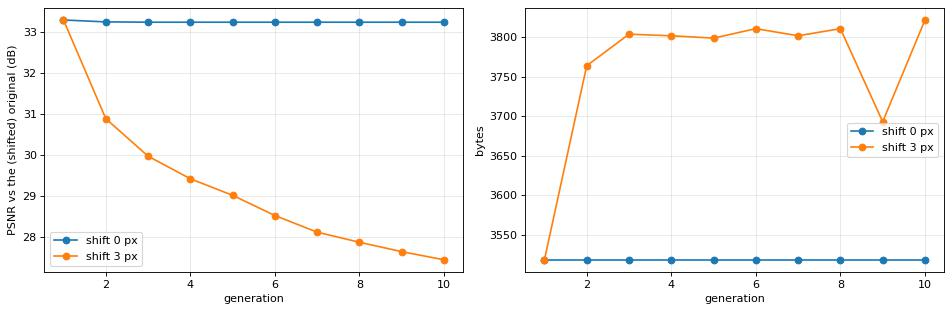

shift 0: PSNR generation 1 -> 10: 33.30 -> 33.24 dB
shift 3: PSNR generation 1 -> 10: 33.30 -> 27.43 dB


In [6]:
def generation_demo(img, n=10, quality=75, shifts=(0, 3), plot=True):
    res = {s: jpeg.generation_loss(img, n=n, quality=quality, shift=s) for s in shifts}
    if plot:
        fig, axs = plt.subplots(1, 2, figsize=(12, 4))
        for s, r in res.items():
            axs[0].plot([g['gen'] for g in r], [g['psnr'] for g in r], 'o-', label=f'shift {s} px')
            axs[1].plot([g['gen'] for g in r], [g['nbytes'] for g in r], 'o-', label=f'shift {s} px')
        axs[0].set_xlabel('generation'); axs[0].set_ylabel('PSNR vs the (shifted) original (dB)'); axs[0].legend(); axs[0].grid(alpha=.3)
        axs[1].set_xlabel('generation'); axs[1].set_ylabel('bytes'); axs[1].legend(); axs[1].grid(alpha=.3)
        plt.tight_layout(); plt.show()
    return res

res_g = generation_demo(clean[:128, :128])
for s, r in res_g.items():
    print(f'shift {s}: PSNR generation 1 -> 10: {r[0]["psnr"]:.2f} -> {r[-1]["psnr"]:.2f} dB')

Re-saving on the same grid costs almost nothing after the first generation; the shifted copy keeps losing quality. The practical lesson is to keep the original and re-export from it rather than editing a JPEG over and over.

## The whole camera: `simulate()` (L2 s3, s34)

`P.simulate` loads a ground-truth scene and runs 13 stages: scene, light, CFA, exposure, ADC, black level, hot pixels, white balance, demosaic, denoise, tone map, sharpen, JPEG. Each record holds the stage output, its meta data and metrics against the truth. `display.render` turns any of them into something you can look at, including the Bayer mosaics and the DN values.

stage          group      domain           shape     PSNR   SSIM       ms
scene          scene      scene     (256, 256, 3)      inf    nan      0.0
illuminant     scene      scene     (256, 256, 3)    11.85  0.772      0.6
cfa            sensor     scene       (256, 256)    13.10  0.680      0.4
exposure       sensor     electrons   (256, 256)    18.44  0.642      7.3
adc            adc        dn          (256, 256)    18.44  0.633      1.1
black_level    processing linear      (256, 256)    18.44  0.633      0.2
hot_pixels     processing linear      (256, 256)    18.49  0.637      6.7
white_balance  processing linear      (256, 256)    33.98  0.922      1.3
demosaic       processing linear    (256, 256, 3)    33.08  0.885     25.3
denoise        processing linear    (256, 256, 3)    34.29  0.934    102.6
tonemap        processing display   (256, 256, 3)    29.14  0.823      1.2
sharpen        processing display   (256, 256, 3)    28.55  0.812      0.8
jpeg           storage    bytes 

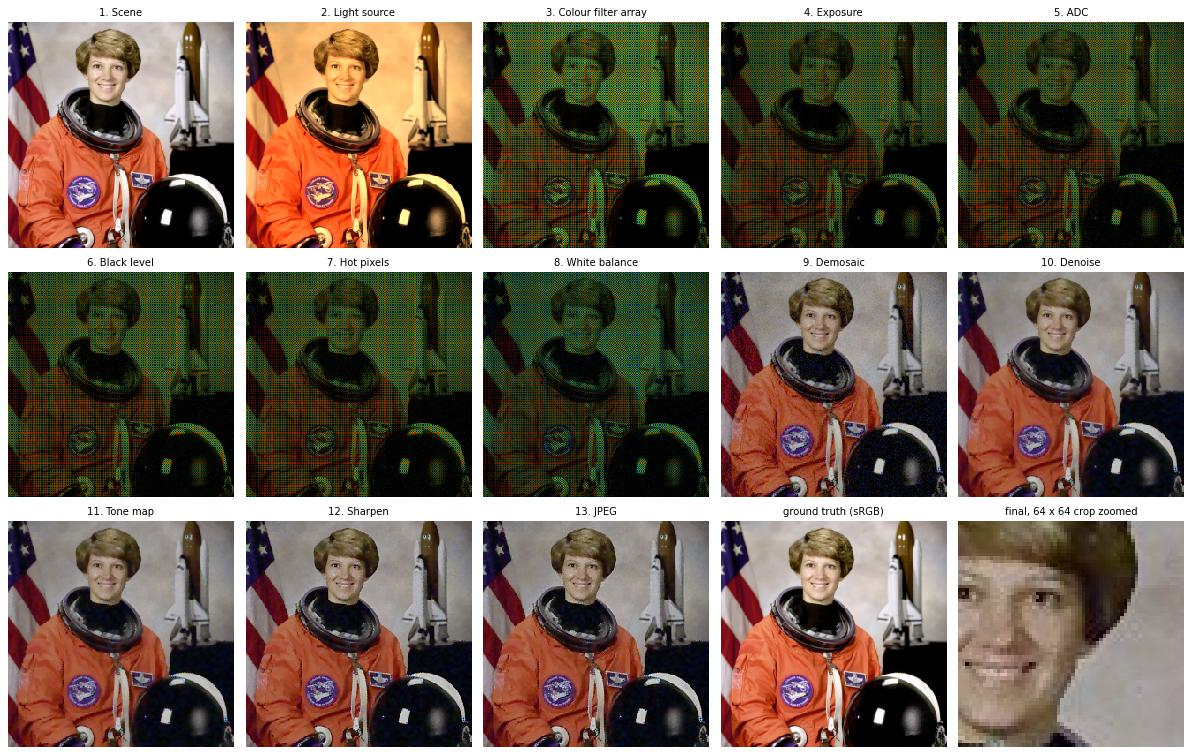

In [7]:
res = P.simulate('astronaut', 256)
print('{:14s} {:10s} {:9s} {:>12s} {:>8s} {:>6s} {:>8s}'.format('stage', 'group', 'domain', 'shape', 'PSNR', 'SSIM', 'ms'))
for rec in res:
    m = rec.metrics
    print('{:14s} {:10s} {:9s} {:>12s} {:8.2f} {:6.3f} {:8.1f}'.format(rec.name, rec.group, rec.meta['domain'], str(rec.image.shape), m['psnr'], m.get('ssim', float('nan')), 1000 * rec.seconds))

def filmstrip(result, truth, plot=True):
    imgs = [(f'{i + 1}. {r.label}', display.render(r)) for i, r in enumerate(result)]
    final = display.render(result.final)
    imgs.append(('ground truth (sRGB)', utils.to_uint8(srgb(truth))))
    imgs.append(('final, 64 x 64 crop zoomed', display.crop_zoom(final, (30, 94, 100, 164), 4)))
    if plot:
        fig, axs = plt.subplots(3, 5, figsize=(15, 9.6))
        for ax, (t, im) in zip(axs.ravel(), imgs):
            ax.imshow(im, interpolation='nearest'); ax.set_title(t, fontsize=9); ax.axis('off')
        plt.tight_layout(); plt.show()
    return imgs

_ = filmstrip(res, scenes.load('astronaut', 256))

Read the strip left to right and top to bottom. The picture starts with a strong orange cast (the 3200 K lamp), becomes a noisy, coloured mosaic at the sensor stages, is cleaned up and colour-corrected by the processing stages, and ends as a JPEG that differs from the truth mainly at fine detail and edges. White balance is the biggest visible step; the mosaic stages look dark because the sensor is run at high ISO and scene white sits at a fraction of the range.

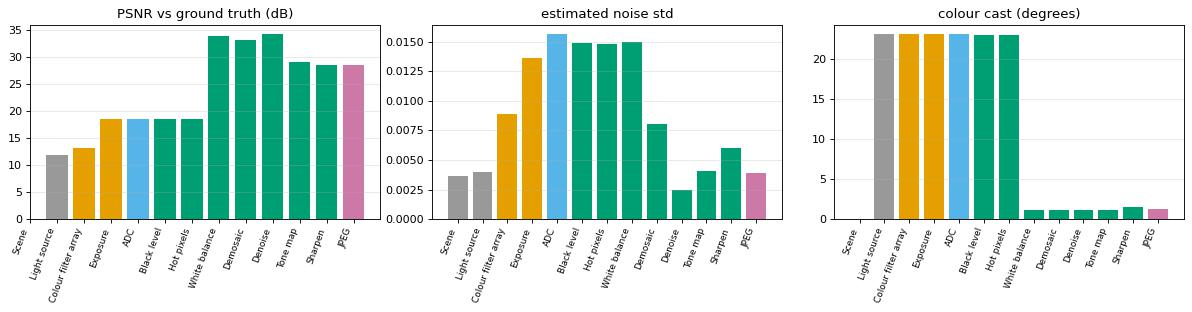

PSNR before / after white balance: 18.5 -> 34.0 dB; colour cast 22.9 -> 1.1 degrees
noise estimate before / after denoise: 0.0080 -> 0.0025


In [8]:
def quality_trace(result, plot=True):
    names = [r.label for r in result]
    keys = [('psnr', 'PSNR vs ground truth (dB)'), ('sigma', 'estimated noise std'), ('cast_deg', 'colour cast (degrees)')]
    vals = {k: np.array([r.metrics.get(k, np.nan) for r in result], float) for k, _ in keys}
    vals['psnr'][~np.isfinite(vals['psnr'])] = np.nan
    if plot:
        fig, axs = plt.subplots(1, 3, figsize=(15, 4))
        cols = {g: P.GROUP_INFO[g]['colour'] for g in P.GROUP_INFO}
        for ax, (k, t) in zip(axs, keys):
            ax.bar(range(len(names)), vals[k], color=[cols[r.group] for r in result])
            ax.set_xticks(range(len(names)), names, rotation=70, ha='right', fontsize=8); ax.set_title(t); ax.grid(axis='y', alpha=.3)
        plt.tight_layout(); plt.show()
    return vals

tr = quality_trace(res)
i_wb = res.names.index('white_balance')
print('PSNR before / after white balance: %.1f -> %.1f dB; colour cast %.1f -> %.1f degrees' % (
    tr['psnr'][i_wb - 1], tr['psnr'][i_wb], tr['cast_deg'][i_wb - 1], tr['cast_deg'][i_wb]))
print('noise estimate before / after denoise: %.4f -> %.4f' % (tr['sigma'][res.names.index('demosaic')], tr['sigma'][res.names.index('denoise')]))

The cast bars show white balance removing the light colour in one step and the PSNR jumping with it; noise appears at the sensor stages and drops at the denoiser; the PSNR later falls where the tone curve amplifies the remaining shadow noise. Stages that do not remove a defect (sharpen, JPEG) trade a small amount of PSNR for appearance or file size.

## Edit a stage and re-run only what changed

Every stage has a dictionary of parameters. If you pass the previous result, `Pipeline.run` copies the prefix of stages whose parameters and input did not change, so moving the sharpen strength recomputes only the last two stages.

In [9]:
def incremental_demo(base, lam=1.0, repeat=3):
    t_full, t_inc = [], []
    for _ in range(repeat):
        t0 = time.perf_counter(); full = P.simulate('astronaut', 256, sharpen={'lam': lam}); t_full.append(time.perf_counter() - t0)
        t0 = time.perf_counter(); inc = P.simulate('astronaut', 256, sharpen={'lam': lam}, previous=base); t_inc.append(time.perf_counter() - t0)
    return full, inc, min(t_full), min(t_inc)

full, inc, tf, ti = incremental_demo(res)
print('stages reused from the previous run:', [r.name for r in inc if r.reused])
print('recomputed:', [r.name for r in inc if not r.reused])
print('identical final image to a full run:', np.array_equal(full.final.image, inc.final.image))
print(f'full run {1000 * tf:.0f} ms, incremental {1000 * ti:.0f} ms; final PSNR {res.final.metrics["psnr"]:.2f} -> {inc.final.metrics["psnr"]:.2f} dB with lam = 1')

stages reused from the previous run: ['scene', 'illuminant', 'cfa', 'exposure', 'adc', 'black_level', 'hot_pixels', 'white_balance', 'demosaic', 'denoise', 'tonemap']
recomputed: ['sharpen', 'jpeg']
identical final image to a full run: True
full run 386 ms, incremental 104 ms; final PSNR 28.48 -> 27.14 dB with lam = 1


The incremental result is identical to a full run, only faster. This is what the interactive widgets below rely on to stay responsive.

## Switching stages off

Each processing stage is there for a reason. Switching one off at a time shows how much of the final quality it buys (`black_level` cannot be skipped because the later stages expect linear data).

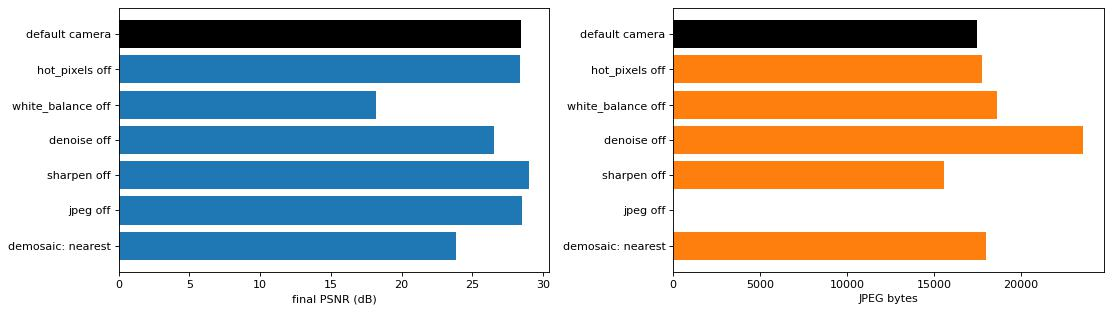

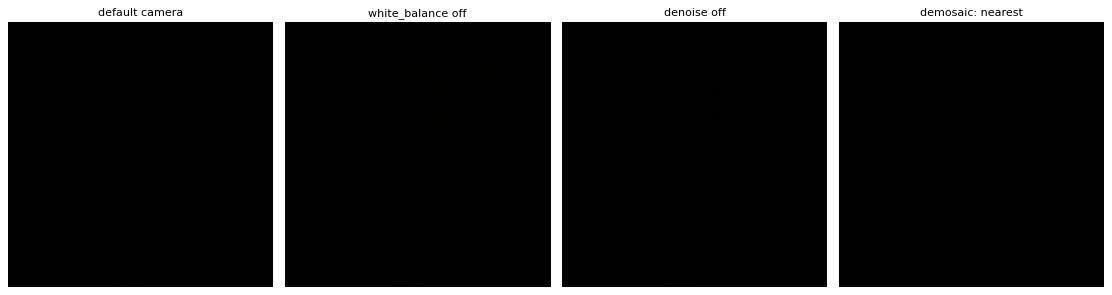

variant                    PSNR    SSIM    bytes
default camera            28.48   0.810    17498
hot_pixels off            28.39   0.805    17785
white_balance off         18.23   0.760    18632
denoise off               26.51   0.702    23611
sharpen off               29.01   0.819    15584
jpeg off                  28.55   0.812      nan
demosaic: nearest         23.84   0.709    18023


In [10]:
def ablation(stages=('hot_pixels', 'white_balance', 'denoise', 'sharpen', 'jpeg'), plot=True):
    base = P.simulate('astronaut', 256)
    rows = {'default camera': base}
    for st in stages:
        rows[f'{st} off'] = P.simulate('astronaut', 256, enabled={st: False})
    rows['demosaic: nearest'] = P.simulate('astronaut', 256, demosaic={'method': 'nearest'})
    table = {k: (r.final.metrics['psnr'], r.final.metrics['ssim'], r.final.meta.get('nbytes', np.nan)) for k, r in rows.items()}
    if plot:
        fig, axs = plt.subplots(1, 2, figsize=(14, 4))
        names = list(table)
        axs[0].barh(names, [v[0] for v in table.values()], color=['k'] + ['tab:blue'] * (len(names) - 1)); axs[0].set_xlabel('final PSNR (dB)'); axs[0].invert_yaxis()
        axs[1].barh(names, [v[2] for v in table.values()], color=['k'] + ['tab:orange'] * (len(names) - 1)); axs[1].set_xlabel('JPEG bytes'); axs[1].invert_yaxis()
        plt.tight_layout(); plt.show()
        pick = ['default camera', 'white_balance off', 'denoise off', 'demosaic: nearest']
        show_row([display.crop_zoom(display.render(rows[k].final), (30, 94, 100, 164), 3) for k in pick], pick, figsize=(14, 4))
    return table

table = ablation()
print('{:22s} {:>8s} {:>7s} {:>8s}'.format('variant', 'PSNR', 'SSIM', 'bytes'))
for k, (p, s, b) in table.items():
    print('{:22s} {:8.2f} {:7.3f} {:8.0f}'.format(k, p, s, b))

White balance is the largest single contribution, because without it the whole picture keeps the lamp's cast. Denoising is worth a few dB and makes the JPEG smaller, since the encoder no longer spends bits on noise. Sharpening is the odd one out: it can lower PSNR and raise the file size, and it is there because the picture looks better.

## Reordering stages

The slide says the processing order may vary (L2 s3). Some orders are forbidden by physics, others legal but worse. We test the legal ones with the same scene and seed, and show what the pipeline says to an illegal one.

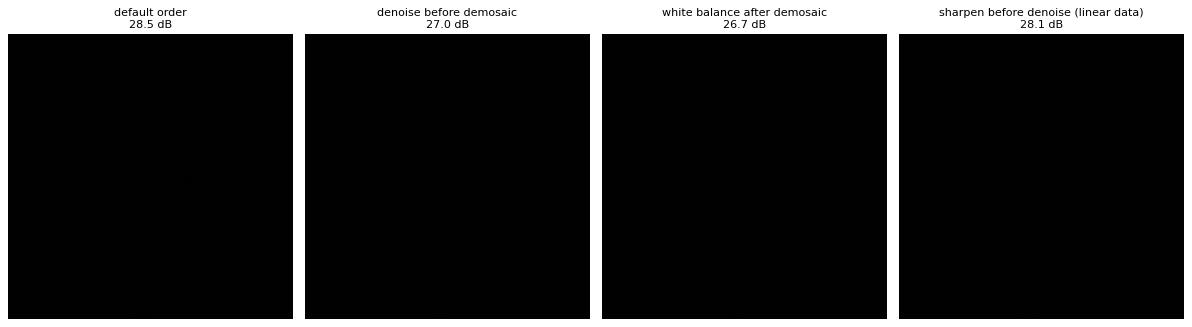

order                                      PSNR    SSIM    bytes  mean diff
default order                             28.49   0.810    17553       0.00
denoise before demosaic                   26.96   0.765    16627       4.65
white balance after demosaic              26.71   0.764    20271       5.21
sharpen before denoise (linear data)      28.07   0.793    17841       2.84

adc before exposure -> stage 'adc' needs data in domain electrons, got 'scene'; check the stage order (adc after exposure, black_level after adc, tonemap after black_level)


In [11]:
def order_experiment(plot=True):
    default = P.default_pipeline(white_balance={'method': 'true'})              # oracle gains so the order, not the estimate, is what changes
    variants = {'default order': default.copy(),
                'denoise before demosaic': default.copy().move('denoise', before='demosaic'),
                'white balance after demosaic': default.copy().move('white_balance', after='demosaic'),
                'sharpen before denoise (linear data)': default.copy().move('sharpen', before='denoise')}
    out = {k: P.simulate('astronaut', 256, pipeline=pl) for k, pl in variants.items()}
    ref = display.render(out['default order'].final).astype(float)
    table = {k: (r.final.metrics['psnr'], r.final.metrics['ssim'], r.final.meta['nbytes'], float(np.abs(display.render(r.final).astype(float) - ref).mean()))
             for k, r in out.items()}
    if plot:
        show_row([display.crop_zoom(display.render(r.final), (30, 94, 100, 164), 3) for r in out.values()],
                 [f'{k}\n{table[k][0]:.1f} dB' for k in out], figsize=(15, 4.4))
    return table

table = order_experiment()
print('{:38s} {:>8s} {:>7s} {:>8s} {:>10s}'.format('order', 'PSNR', 'SSIM', 'bytes', 'mean diff'))
for k, (p, s, b, d) in table.items():
    print('{:38s} {:8.2f} {:7.3f} {:8d} {:10.2f}'.format(k, p, s, b, d))

bad = P.default_pipeline().move('adc', before='exposure')                         # electrons do not exist yet
try:
    P.simulate('astronaut', 128, pipeline=bad)
except ValueError as e:
    print('\nadc before exposure ->', e)

Denoising before demosaicing is worse: each colour plane is a quarter or half of the pixels and the filter cannot use the other channels. Doing the white balance after the demosaic changes the result because the median demosaicer works on colour differences, so it prefers to see balanced channels. Sharpening noisy linear data before the denoiser loses against the default order. The sensor half of the chain (exposure, ADC, black level) has only one valid order, and the stage tells you so by name.

## Interactive: the whole camera

Pick the ISO, the white-balance method, the denoiser's range sigma (0 switches it off) and the JPEG quality. The simulation uses `previous=`, so changing only the JPEG quality or the sharpen strength is quick. The title reports the final PSNR, the file size and how many stages were recomputed.

In [12]:
_cache = {}

def camera_view(iso=3200, wb_method='white_patch', denoise_sigma_r=0.05, jpeg_quality=85):
    ov = dict(adc={'iso': iso}, white_balance={'method': wb_method}, jpeg={'quality': jpeg_quality})
    if denoise_sigma_r <= 0:
        ov['enabled'] = {'denoise': False}
    else:
        ov['denoise'] = {'sigma_d': 1.5, 'sigma_r': denoise_sigma_r}
    r = P.simulate('astronaut', 192, previous=_cache.get('prev'), **ov)
    _cache['prev'] = r
    n_new = sum(not s.reused for s in r)
    img = display.render(r.final)
    fig, axs = plt.subplots(1, 2, figsize=(10, 4.4), gridspec_kw=dict(width_ratios=[1, 1]))
    axs[0].imshow(img); axs[0].axis('off')
    axs[0].set_title(f"{r.final.metrics['psnr']:.1f} dB, SSIM {r.final.metrics['ssim']:.2f}, {r.final.meta['nbytes']} B, {n_new} of {len(r)} stages recomputed", fontsize=9)
    axs[1].imshow(display.crop_zoom(img, (20, 84, 70, 134), 4), interpolation='nearest'); axs[1].axis('off'); axs[1].set_title('crop', fontsize=9)
    plt.tight_layout(); plt.show()

W.interact(camera_view, iso=W.SelectionSlider(options=[100, 200, 400, 800, 1600, 3200, 6400, 12800], value=3200),
           wb_method=['none', 'gray_world', 'white_patch', 'true'], denoise_sigma_r=W.FloatSlider(min=0, max=0.2, step=0.01, value=0.05),
           jpeg_quality=W.IntSlider(min=5, max=100, step=5, value=85));

interactive(children=(SelectionSlider(description='iso', index=5, options=(100, 200, 400, 800, 1600, 3200, 640…

## Try it

1. Use `P.simulate('astronaut', 256, adc={'iso': 200}, exposure={'exposure': 0.2})` to get a low-noise capture at about the same brightness as the default. How many dB does it gain over the default, and which stages hold the gain?
2. Run the camera on `scenes.sunset(256)` with the three white-balance methods and compare the final PSNR (use `method='true'` as the reference).
3. Move `sharpen` before `tonemap` on a copy of the pipeline (`move('sharpen', before='tonemap')`). The data is now linear; what happens to the halos and to the PSNR?

In [13]:
# Exercises 1-3: edit and re-run
a = P.simulate('astronaut', 256)
b = P.simulate('astronaut', 256, adc={'iso': 200}, exposure={'exposure': 0.2})
print('default %.2f dB | low ISO, long exposure %.2f dB' % (a.final.metrics['psnr'], b.final.metrics['psnr']))
for m in ('gray_world', 'white_patch', 'true'):
    r = P.simulate('sunset', 256, white_balance={'method': m})
    print('sunset, %-11s %.2f dB, wb error %s deg' % (m, r.final.metrics['psnr'], r['white_balance'].metrics.get('wb_angular_error', r['white_balance'].meta.get('wb_angular_error'))))
pl = P.default_pipeline().move('sharpen', before='tonemap')
print('sharpen before tonemap: %.2f dB' % P.simulate('astronaut', 256, pipeline=pl).final.metrics['psnr'])

default 28.48 dB | low ISO, long exposure 30.70 dB


sunset, gray_world  22.73 dB, wb error 15.001673941087256 deg


sunset, white_patch 11.81 dB, wb error 19.784797008675856 deg


sunset, true        33.36 dB, wb error 0.0 deg


sharpen before tonemap: 27.78 dB
